In [201]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl


.pkl means pickle python serial format (save can use it later)


In [202]:
import pandas as pd
df=pd.read_pickle("/kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl")

In [203]:
flag1 = 0
flag2=0

supose either data is in formot [["trainig"]] so we check x>0 means it is array ornt then x[0]>0 to check if 2d x[0][0]>0 to check 2d has element 


In [204]:
if flag1 == 0:
    df["failureType"]=df["failureType"].apply(lambda x: str(x[0][0]) if len(x)>0 and len(x[0])>0 and len(x[0][0])>0 else str(x))
    
    flag1=1

In [205]:
df.iloc[0:5]#to see first 5 element in the dataset panda

,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,[[Training]],none
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,[[Training]],none
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,[[Training]],none
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4.0,[[Training]],none
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5.0,[[Training]],none


In [206]:
#only 1,2,0 is in wafermap so i dont think it is a good idea to normalize it 

In [207]:
if flag2==0:
    df["trianTestLabel"]=df["trianTestLabel"].apply(lambda x: str(x[0][0]) if len(x)>0 and len(x[0][0])>0 and len(x[0])>0  else str(x))
    flag2=1




In [208]:
df["trianTestLabel"].iloc[0]
df.iloc[0:3]

,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1.0,Training,none
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2.0,Training,none
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3.0,Training,none


In [209]:
import matplotlib.pyplot as plt

In [210]:
wafer=df["waferMap"].iloc[0]
print(type(wafer))
print(np.array(wafer).shape)


<class 'numpy.ndarray'>
(45, 48)


In [211]:
k=df["trianTestLabel"].iloc[0]
print(type(k))


<class 'str'>


In [212]:
df["trianTestLabel"].value_counts()

trianTestLabel
[]          638507
Test        118595
Training     54355
Name: count, dtype: int64

We know that test data is 118595 and train data is 54355 and rest unlabbeled

In [213]:
df["failureType"].value_counts()

failureType
[]           638507
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64

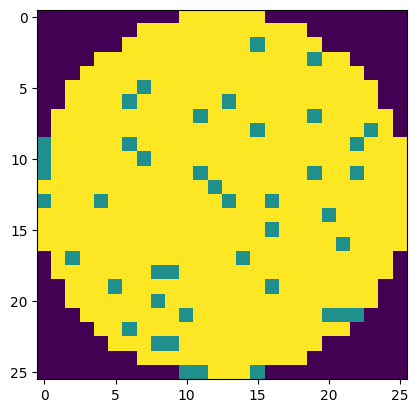

In [214]:
l=df[df["failureType"]=="Near-full"]["waferMap"].iloc[0]
plt.imshow(l)

for custom dataset we need a dict and list to do both vica vera item to idenx and index to item 

In [215]:
# for now we are ignoring unlabbeled data 
test_dataset=df[df["trianTestLabel"]=="Test"].copy()
train_dataset=df[df["trianTestLabel"]=="Training"].copy()


In [216]:
#making list
label_list=train_dataset["failureType"].unique().tolist()
label_list

['none',
 'Loc',
 'Edge-Loc',
 'Center',
 'Edge-Ring',
 'Scratch',
 'Random',
 'Near-full',
 'Donut']

In [217]:
#making dict
label_dict=dict();
for i,j in enumerate(label_list):
    label_dict[j]=i;
label_dict
    
    
    

{'none': 0,
 'Loc': 1,
 'Edge-Loc': 2,
 'Center': 3,
 'Edge-Ring': 4,
 'Scratch': 5,
 'Random': 6,
 'Near-full': 7,
 'Donut': 8}

In [218]:
import torch
from torch.utils.data import DataLoader,Dataset
from torchvision import datasets,transforms


In [219]:
train_dataset.iloc[0]
z=train_dataset["waferMap"].apply(lambda x : x.shape)
z.value_counts()

waferMap
(25, 27)      15684
(27, 25)       9235
(26, 26)       6369
(38, 36)       1877
(33, 37)       1804
              ...  
(64, 61)          1
(122, 102)        1
(75, 77)          1
(67, 65)          1
(63, 63)          1
Name: count, Length: 335, dtype: int64

335 different image size is there 

In [220]:
height = z.apply(lambda x: x[0])
width=z.apply(lambda x : x[1])
print("height")
print(height.quantile([0.50,0.90,0.95,0.99,1.00]))
print("\nwidth")
print(width.quantile([0.50,0.90,0.95,0.99,1.00]))

height
0.50     27.0
0.90     56.0
0.95     64.0
0.99    107.0
1.00    212.0
Name: waferMap, dtype: float64

width
0.50     27.0
0.90     59.0
0.95     66.0
0.99    150.0
1.00    204.0
Name: waferMap, dtype: float64


from here we can know 95 percent have size less than 64*59

In [221]:
#transform function
#warning : To tensor divides all data by 255 keep it in mind 
transform_func=transforms.Compose(
    [
        # transforms.ToTensor(),
        # transforms.Resize(size=(64,64)),
        
        transforms.Lambda(
            lambda x: torch.from_numpy(np.asarray(x)).float().unsqueeze(0) # unsqueeze to add simesion
        ),
        transforms.Resize(
            (64,64),
            interpolation=transforms.InterpolationMode.NEAREST # it resize by copying nearest pixel
            
        ),
        
        
        
        
        
        transforms.RandomHorizontalFlip(p=0.3),
        transforms.RandomVerticalFlip(p=0.3),
        transforms.RandomRotation(10),
        
        
        
    ]
)
test_transform=transforms.Compose(
    [
        # transforms.ToTensor(),
        # transforms.Resize(size=(64,64)),
         transforms.Lambda(
            lambda x: torch.from_numpy(np.asarray(x)).float().unsqueeze(0) # unsqueeze to add simesion
        ),
        transforms.Resize(
            (64,64),
            interpolation=transforms.InterpolationMode.NEAREST # it resize by copying nearest pixel
            
        )
        
        
    ]
)

In [222]:
#custom dataset
class pklCustom(Dataset):
    def __init__(self,dataset,transform=None):#only runs one time we can expnad dims here
        self.dataset=dataset
        self.transform=transform
        self.mapper=label_dict
        
        
    def __len__(self) -> int:
        return len(self.dataset)
    def __getitem__(self,index):
        array=self.dataset["waferMap"].iloc[index]
        class_name=self.dataset["failureType"].iloc[index]
        # we need it to give class index not complete class name
        
        class_idx=self.mapper[class_name]
        if self.transform:
            return self.transform(array),class_idx
        else:
            return array,class_idx
                
        
        
        
    


In [223]:
train_dataset_obj=pklCustom(dataset=train_dataset,
                           transform=transform_func)
test_dataset_obj=pklCustom(dataset=test_dataset,
                          transform=test_transform)

In [224]:
from torch.utils.data import DataLoader
BATCH_SIZE=256
NUM_WORKERS=os.cpu_count()
train_dataloader=DataLoader(dataset=train_dataset_obj,
                           batch_size=BATCH_SIZE,
                            num_workers=NUM_WORKERS,
                           shuffle=True)
test_dataloader=DataLoader(dataset=test_dataset_obj,
                           batch_size=BATCH_SIZE,
                           num_workers=NUM_WORKERS
                          )

In [225]:
#checking for the first batch 
img_custom,label_custom=next(iter(train_dataloader))
img_custom.shape,label_custom.shape

(torch.Size([256, 1, 64, 64]), torch.Size([256]))

In [226]:
#checking for the first batch 
img_custom,label_custom=next(iter(test_dataloader))
img_custom.shape,label_custom.shape

(torch.Size([256, 1, 64, 64]), torch.Size([256]))

In [227]:
import torch 
import torch.nn as nn

In [228]:
#starting from tinyvgg model
#stride = 1 is default move 1 pixel at a time
#kernel=3 check 3*3 square at a time
class TinyVGG(nn.Module):
    def __init__(self,in_channels,hidden_units,output_shape):
        super().__init__()
        self.conv_block_1=nn.Sequential(
            nn.Conv2d(in_channels,hidden_units,kernel_size=3,stride=1,padding=1),#learn pattern in img 
            nn.BatchNorm2d(hidden_units),#try to keep mean close to 0 and std =1
            nn.ReLU(),
            nn.Conv2d(hidden_units,hidden_units*2,kernel_size=3,stride=1,padding=1),#learn pattern in img 
            nn.BatchNorm2d(hidden_units*2),#try to keep mean close to 0 and std =1
            nn.ReLU(),
            nn.MaxPool2d(2) # take 2*2 area and keep max value
            )
        self.conv_block_2=nn.Sequential(
            nn.Conv2d(hidden_units*2,hidden_units*4,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(hidden_units*4),
            nn.ReLU(),
            nn.Conv2d(hidden_units*4,hidden_units*8,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(hidden_units*8),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier=nn.Sequential(
            nn.AdaptiveAvgPool2d((4,4)),# dual benifit i need not to know input size of length and breadth also it takes 16*16 here and create a 4*4 here thus reduce paarmertes
            nn.Flatten(),#take multidimestion make a large vector
            nn.Linear(in_features=(hidden_units*8)*4*4,
                      out_features=output_shape)
            
        )
    def forward(self,x):
        x=self.conv_block_1(x)
        x=self.conv_block_2(x)
        x=self.classifier(x)
        return x
        

        

In [229]:
torch.manual_seed(42)
model_tinyvgg=TinyVGG(in_channels=1,# no of color chaneels
                      hidden_units = 10,
                      output_shape=len(label_list)
)
model_tinyvgg

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(10, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(10, 20, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(20, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(20, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(40, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0):

In [230]:
import torchinfo 
from torchinfo import summary
summary(model_tinyvgg,input_size=[32,1,64,64])

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [32, 9]                   --
├─Sequential: 1-1                        [32, 20, 32, 32]          --
│    └─Conv2d: 2-1                       [32, 10, 64, 64]          100
│    └─BatchNorm2d: 2-2                  [32, 10, 64, 64]          20
│    └─ReLU: 2-3                         [32, 10, 64, 64]          --
│    └─Conv2d: 2-4                       [32, 20, 64, 64]          1,820
│    └─BatchNorm2d: 2-5                  [32, 20, 64, 64]          40
│    └─ReLU: 2-6                         [32, 20, 64, 64]          --
│    └─MaxPool2d: 2-7                    [32, 20, 32, 32]          --
├─Sequential: 1-2                        [32, 80, 16, 16]          --
│    └─Conv2d: 2-8                       [32, 40, 32, 32]          7,240
│    └─BatchNorm2d: 2-9                  [32, 40, 32, 32]          80
│    └─ReLU: 2-10                        [32, 40, 32, 32]          --
│    └─C

In [231]:

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [232]:
model_tinyvgg = nn.DataParallel(model_tinyvgg)# to use both gpu 

In [233]:
def test_step(model: torch.nn.Module , dataloader: torch.utils.data.DataLoader ,loss_fn: torch.nn.Module,device=device):
    model.eval()
    test_loss,test_acc=0,0
    with torch.inference_mode():
        for batch,(X,y) in enumerate(dataloader):
            X,y=X.to(device),y.to(device)
            y_pred=model(X)
            loss=loss_fn(y_pred,y)
            test_loss+=loss.item()
            y_pred_class=y_pred.argmax(dim=1)
            test_acc += (y_pred_class == y).sum().item()/len(y)
        test_loss= test_loss/len(dataloader)
        test_acc=test_acc/len(dataloader)
        return test_loss,test_acc
            

In [234]:
def train_step(model: torch.nn.Module ,dataloader: torch.utils.data.DataLoader,loss_fn: torch.nn.Module,optimizer:torch.optim.Optimizer,device=device):
    model.train()
    train_loss=0
    train_acc=0
    for batch,(X,y) in enumerate(dataloader):
        X,y=X.to(device),y.to(device)
        y_pred=model(X)#this is logit
        loss=loss_fn(y_pred,y)
        train_loss += loss.item()
        optimizer.zero_grad()
        loss.backward()
        #our model is learning absurdly so we need to scale if it become too big 
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )
        optimizer.step()
        y_pred_class=torch.argmax(torch.softmax(y_pred,dim=1),dim=1)
        train_acc += (y_pred_class == y).sum().item()/len(y)#for each 32 in 1 iter of dataloader
    train_loss= train_loss/len(dataloader)#total dataloader
    train_acc = train_acc/len(dataloader)
    return train_loss,train_acc
        
        
    

In [235]:
import torch
import torch.nn as nn
from tqdm.auto import tqdm


def train(
    model: torch.nn.Module,
    train_dataloader: torch.utils.data.DataLoader,
    test_dataloader: torch.utils.data.DataLoader,
    optimizer: torch.optim.Optimizer,
    loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
    epochs: int = 20,
    device=device,
):
   
    results = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": [],
    }

    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(
            model=model,
            dataloader=train_dataloader,
            loss_fn=loss_fn,
            optimizer=optimizer,
            device=device,
        )

        test_loss, test_acc = test_step(
            model=model,
            dataloader=test_dataloader,
            loss_fn=loss_fn,
            device=device,
        )

        print(
            f"Epoch: {epoch+1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc*100:.2f}% | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc*100:.2f}%"
        )

        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

    return results

In [236]:
#for Tiny Vgg 
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.AdamW(
    params=model_tinyvgg.parameters(),lr=0.003,weight_decay=1e-4
 # will learn slowly take slow step
)

In [237]:
class_counts=train_dataset["failureType"].value_counts()
total=len(train_dataset)
num_classes=len(label_list)
class_weights=[]
for class_name,class_idx in label_dict.items():
    weight=total/(num_classes * class_counts[class_name])
    class_weights.append(weight)

In [238]:
class_weights=torch.tensor(class_weights,dtype=torch.float32)# since  ratio / proportion is very bad


In [239]:
loss_fn=nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

In [240]:
print(class_counts)
print(class_weights)

failureType
none         36730
Edge-Ring     8554
Center        3462
Edge-Loc      2417
Loc           1620
Random         609
Scratch        500
Donut          409
Near-full       54
Name: count, dtype: int64
tensor([  0.1644,   3.7281,   2.4987,   1.7445,   0.7060,  12.0789,   9.9170,
        111.8416,  14.7664])


In [ ]:
train(model_tinyvgg,train_dataloader,test_dataloader,optimizer,loss_fn)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.9843 | train_acc: 70.08% | test_loss: 1.2357 | test_acc: 43.57%
Epoch: 2 | train_loss: 0.6294 | train_acc: 81.23% | test_loss: 1.5851 | test_acc: 55.06%
Epoch: 3 | train_loss: 0.4782 | train_acc: 83.25% | test_loss: 1.3955 | test_acc: 64.30%
Epoch: 4 | train_loss: 0.4830 | train_acc: 83.85% | test_loss: 1.7085 | test_acc: 92.68%
Epoch: 5 | train_loss: 0.4100 | train_acc: 85.81% | test_loss: 1.3514 | test_acc: 78.60%
Epoch: 6 | train_loss: 0.3540 | train_acc: 87.87% | test_loss: 2.3173 | test_acc: 89.93%
Epoch: 7 | train_loss: 0.3391 | train_acc: 89.01% | test_loss: 0.9175 | test_acc: 80.72%
Epoch: 8 | train_loss: 0.3091 | train_acc: 90.04% | test_loss: 1.3054 | test_acc: 55.58%
Epoch: 9 | train_loss: 0.2943 | train_acc: 90.40% | test_loss: 1.1222 | test_acc: 86.13%
Epoch: 10 | train_loss: 0.2830 | train_acc: 91.11% | test_loss: 0.8516 | test_acc: 94.62%
Epoch: 11 | train_loss: 0.2758 | train_acc: 91.55% | test_loss: 0.8078 | test_acc: 82.57%
Epoch: 12 | train_l

In [ ]:
# here since max data is none so it is not predicting correctly we will use approches

| Approach              | Changes what?               |
| --------------------- | --------------------------- |
| Class-weighted CE     | **Loss importance**         |
| WeightedRandomSampler | **Training samples**        |
| Focal Loss            | **Hard-example importance** |
| Augmentation          | **Training data variety**   |
| Over/undersampling    | **Class frequency**         |


In [ ]:
!pip install torchmetrics mlxtend

In [ ]:
import torch
y_preds=[]
y_targets=[]
model_tinyvgg.eval()
with torch.inference_mode():
    for X,y in test_dataloader:
        X=X.to(device)
        logits=model_tinyvgg(X)
        preds=logits.argmax(dim=1)
        y_preds.append(preds.cpu())
        y_targets.append(y.cpu())
    y_pred_tensor=torch.cat(y_preds)
    y_target_tensor=torch.cat(y_targets)
        


In [ ]:
#Confusion Matrix
from torchmetrics import ConfusionMatrix
import mlxtend 
from mlxtend.plotting import plot_confusion_matrix
confmat=ConfusionMatrix(task="multiclass",num_classes=len(label_list))
confmat_tensor=confmat(preds=y_pred_tensor,target=y_target_tensor)
fig,ax=plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(),
    class_names=label_list,
    figsize=(10,7)
)

